# 04 — SOTA-comparable building-type dataset

**Why this notebook.** True building-type SOTA (often **86–96%** accuracy on 10–12 classes) uses
**street-view / VHR imagery + multi-modal graphs**, not AlphaEarth alone. Notebook 02’s binary
residential probe (~83% pooled / ~77% leave-one-region-out) sits below that for expected reasons
(64-D @ 10 m + logistic regression).

This notebook builds a **fairer comparison dataset**:

1. **Fine-grained building-type labels** from Overture `class` (high-precision OSM tags only).
2. **AlphaEarth Satellite Embedding V1** (2024) at each footprint centroid.
3. A **multi-modal-ready schema** (WKT footprint, lon/lat, height/floors) so street-view / VHR /
   neighbor-graph features can be joined later without resampling labels.

**Next step (analysis):** train a simple classifier on AlphaEarth-only features and report
multi-class metrics against the SOTA ballpark — not claiming the same modalities.

**Requires.** EE auth (`earthengine authenticate --auth_mode=notebook`) + `EE_PROJECT`; network for Overture S3.


## Setup


In [1]:
from __future__ import annotations

import json
import os
import time
import warnings
from pathlib import Path

import duckdb
import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

OUT_DIR = ROOT / "outputs" / "sota_building_type"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
EMBED_YEAR = 2024
N_PER_CLASS = 80          # per Overture class per region (trial; raise for full runs)
EE_BATCH = 400
RANDOM_STATE = 42
EE_PROJECT = os.environ.get("EE_PROJECT", "ee-kedarvaidya0504")

print("ROOT:", ROOT)
print("OUT_DIR:", OUT_DIR)
print("EE_PROJECT:", EE_PROJECT)


/home/kv133/Alpha-Earth-Embeddings-Research/.venv/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT_DIR: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type
EE_PROJECT: ee-kedarvaidya0504


**Result.** Environment ready. Outputs go to `outputs/sota_building_type/`; EE project is `ee-kedarvaidya0504`. (Python 3.10 warning is harmless.)

## Study taxonomy (SOTA-style multi-class)

Maps high-precision Overture `class` values onto a compact **8-way** label set used in many
building-type papers. Ambiguous tags (`residential`, `terrace`, bare `building=yes`) are **excluded**
so GT stays high-precision / lower-recall — the right setup for SOTA-style comparison.


In [2]:
# Overture class → study label (high-precision only)
CLASS_TO_LABEL: dict[str, str] = {
    # single-family
    "house": "single_family",
    "detached": "single_family",
    "bungalow": "single_family",
    "semi": "single_family",
    "semidetached_house": "single_family",
    # multi-family
    "apartments": "multi_family",
    "dormitory": "multi_family",
    # commercial / lodging
    "retail": "retail",
    "commercial": "retail",
    "supermarket": "retail",
    "hotel": "hotel",
    # office
    "office": "office",
    # industrial
    "industrial": "industrial",
    "warehouse": "industrial",
    "manufacture": "industrial",
    # education
    "school": "education",
    "kindergarten": "education",
    "college": "education",
    "university": "education",
    # medical
    "hospital": "medical",
    "clinic": "medical",
    # civic / religious
    "church": "religious",
    "cathedral": "religious",
    "mosque": "religious",
    "temple": "religious",
    "synagogue": "religious",
    "civic": "civic",
    "government": "civic",
    "public": "civic",
    "fire_station": "civic",
    "police": "civic",
}

LABEL_ORDER = [
    "single_family",
    "multi_family",
    "retail",
    "hotel",
    "office",
    "industrial",
    "education",
    "medical",
    "religious",
    "civic",
]

# Binary rollup for continuity with notebook 02
RESIDENTIAL_LABELS = {"single_family", "multi_family"}

print("Mapped Overture classes:", len(CLASS_TO_LABEL))
print("Study labels:", LABEL_ORDER)


Mapped Overture classes: 31
Study labels: ['single_family', 'multi_family', 'retail', 'hotel', 'office', 'industrial', 'education', 'medical', 'religious', 'civic']


**Result.** Taxonomy ready: **31** Overture classes → **10** study labels (e.g. house→single_family, apartments→multi_family). Ambiguous tags like bare `residential` are excluded on purpose.

## US metros (street-view dense → future multi-modal)

AOIs are compact downtown/near-downtown boxes where OSM class tags and Google Street View
coverage are both relatively dense — useful when we later attach GSV / VHR / graph neighbors.


In [3]:
US_REGIONS: dict[str, tuple[float, float, float, float]] = {
    # (xmin, ymin, xmax, ymax)
    "Boston_NE": (-71.20, 42.28, -70.95, 42.42),
    "NYC_NE": (-74.05, 40.68, -73.90, 40.82),
    "Chicago_MW": (-87.75, 41.80, -87.55, 41.95),
    "Atlanta_SE": (-84.45, 33.70, -84.30, 33.85),
    "Houston_S": (-95.50, 29.70, -95.25, 29.85),
    "Denver_W": (-105.05, 39.68, -104.90, 39.80),
    "Phoenix_SW": (-112.15, 33.40, -111.95, 33.55),
    "Seattle_NW": (-122.40, 47.55, -122.25, 47.68),
    "LA_W": (-118.35, 34.00, -118.20, 34.12),
    "SF_W": (-122.45, 37.74, -122.38, 37.81),
}


def region_centroid(bbox: tuple[float, float, float, float]) -> tuple[float, float]:
    xmin, ymin, xmax, ymax = bbox
    return (0.5 * (xmin + xmax), 0.5 * (ymin + ymax))


region_meta = pd.DataFrame(
    [
        {
            "region": name,
            "lon": region_centroid(b)[0],
            "lat": region_centroid(b)[1],
            "xmin": b[0],
            "ymin": b[1],
            "xmax": b[2],
            "ymax": b[3],
        }
        for name, b in US_REGIONS.items()
    ]
)
region_meta


,region,lon,lat,xmin,ymin,xmax,ymax
0,Boston_NE,-71.075,42.350,-71.200,42.280,-70.950,42.420
1,NYC_NE,-73.975,40.750,-74.050,40.680,-73.900,40.820
2,Chicago_MW,-87.650,41.875,-87.750,41.800,-87.550,41.950
3,Atlanta_SE,-84.375,33.775,-84.450,33.700,-84.300,33.850
4,Houston_S,-95.375,29.775,-95.500,29.700,-95.250,29.850
5,Denver_W,-104.975,39.740,-105.050,39.680,-104.900,39.800
6,Phoenix_SW,-112.050,33.475,-112.150,33.400,-111.950,33.550
7,Seattle_NW,-122.325,47.615,-122.400,47.550,-122.250,47.680
8,LA_W,-118.275,34.060,-118.350,34.000,-118.200,34.120
9,SF_W,-122.415,37.775,-122.450,37.740,-122.380,37.810


**Result.** Defined **10 US metro AOIs** (adds San Francisco vs notebook 02/03). Compact boxes chosen for denser OSM tags and future street-view coverage.

## 1. Sample Overture buildings (high-precision classes only)


In [4]:
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("SET s3_region='us-west-2';")
con.execute("SET s3_access_key_id='';")
con.execute("SET s3_secret_access_key='';")
print("DuckDB ready ·", RELEASE)


def sample_region(name: str, bbox: tuple[float, float, float, float], n_per_class: int) -> pd.DataFrame:
    """Pull high-precision Overture buildings whose class maps into STUDY_TAXONOMY."""
    xmin, ymin, xmax, ymax = bbox
    class_list = ", ".join(f"'{c}'" for c in sorted(CLASS_TO_LABEL))
    sql = f"""
    WITH b AS (
      SELECT
        id,
        subtype,
        class,
        sources,
        height,
        num_floors,
        ST_X(ST_Centroid(geometry)) AS lon,
        ST_Y(ST_Centroid(geometry)) AS lat,
        ST_AsText(geometry) AS wkt,
        ST_Area(ST_Transform(geometry, 'EPSG:3857')) AS area_m2_approx
      FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
      WHERE bbox.xmin BETWEEN {xmin} AND {xmax}
        AND bbox.ymin BETWEEN {ymin} AND {ymax}
        AND class IS NOT NULL
        AND class IN ({class_list})
        AND geometry IS NOT NULL
    ),
    filtered AS (
      SELECT * FROM b
      WHERE lon BETWEEN {xmin} AND {xmax}
        AND lat BETWEEN {ymin} AND {ymax}
    ),
    sampled AS (
      SELECT * FROM (
        SELECT *, row_number() OVER (PARTITION BY class ORDER BY hash(id)) AS rn
        FROM filtered
      ) t
      WHERE rn <= {n_per_class}
    )
    SELECT
      id,
      '{name}' AS region,
      subtype,
      class,
      sources,
      height,
      num_floors,
      lon,
      lat,
      wkt,
      area_m2_approx
    FROM sampled
    """
    return con.execute(sql).df()


cache_labels = OUT_DIR / "buildings_labeled.parquet"
if cache_labels.exists():
    raw = pd.read_parquet(cache_labels)
    print("Loaded cached labels:", cache_labels)
else:
    frames = []
    for name, bbox in US_REGIONS.items():
        print(f"Sampling · {name} ...", flush=True)
        try:
            frames.append(sample_region(name, bbox, N_PER_CLASS))
        except Exception as e:
            print(f"  FAILED {name}: {e}")
    raw = pd.concat(frames, ignore_index=True)
    raw.to_parquet(cache_labels, index=False)
    print("Wrote", cache_labels)

print("raw n =", len(raw))
raw.head()


DuckDB ready · 2026-08-19.0
Sampling · Boston_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · NYC_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · Chicago_MW ...


...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · SF_W ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/buildings_labeled.parquet
raw n = 11280


,id,region,subtype,class,sources,height,num_floors,lon,lat,wkt,area_m2_approx
0,b1b2cd95-8fc4-4696-a969-deeb58f4880e,Boston_NE,religious,cathedral,"[{'property': '', 'dataset': 'OpenStreetMap', ...",30.900,<NA>,-71.070,42.341,"POLYGON ((-71.0691591 42.3407175, -71.0691067 ...",4230.863
1,27a715f5-554f-4dc7-8fc1-8b99a868eac4,Boston_NE,religious,synagogue,"[{'property': '', 'dataset': 'OpenStreetMap', ...",21.400,<NA>,-71.094,42.349,"POLYGON ((-71.0942632 42.3494419, -71.0942886 ...",327.505
2,4f545da6-5591-4219-aa39-4b753d4e44cb,Boston_NE,religious,synagogue,"[{'property': '', 'dataset': 'OpenStreetMap', ...",11.800,<NA>,-71.109,42.340,"POLYGON ((-71.1096112 42.3403688, -71.1090649 ...",6903.127
3,8e328eef-43e6-440b-ac07-fee253dd264b,Boston_NE,religious,synagogue,"[{'property': '', 'dataset': 'OpenStreetMap', ...",25.500,<NA>,-71.126,42.344,"POLYGON ((-71.1262735 42.3443623, -71.1263609 ...",3755.140
4,19af6b04-00a9-406e-8e77-9fe94f64ecd9,Boston_NE,religious,synagogue,"[{'property': '', 'dataset': 'OpenStreetMap', ...",10.800,<NA>,-71.153,42.340,"POLYGON ((-71.1529831 42.3397204, -71.15251 42...",1538.255


**Result.** Queried Overture across 10 metros and saved **11,280** high-precision class-tagged footprints (with WKT polygons, height when available).

In [5]:
# Attach study labels + binary residential flag
labels = raw.copy()
labels["label"] = labels["class"].map(CLASS_TO_LABEL)
labels = labels.dropna(subset=["label"]).reset_index(drop=True)
labels["y_res"] = labels["label"].isin(RESIDENTIAL_LABELS).astype(int)

# Keep a compact source flag if present
def primary_source(sources) -> str | None:
    try:
        if sources is None or (isinstance(sources, float) and np.isnan(sources)):
            return None
        if isinstance(sources, str):
            s = json.loads(sources)
        else:
            s = sources
        if isinstance(s, list) and s:
            return str(s[0].get("dataset") or s[0].get("record_id") or s[0])[:80]
        return str(s)[:80]
    except Exception:
        return None

if "sources" in labels.columns:
    labels["source_primary"] = labels["sources"].map(primary_source)

counts = (
    labels.groupby(["region", "label"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[c for c in LABEL_ORDER if c in labels["label"].unique()], fill_value=0)
)
counts_by_region = labels.groupby("region").size().rename("n").to_frame()
counts_path = OUT_DIR / "label_counts_by_region.csv"
counts.to_csv(counts_path)
print("Wrote", counts_path)
print("Total labeled buildings:", len(labels))
print("Label distribution:")
print(labels["label"].value_counts())
counts


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/label_counts_by_region.csv
Total labeled buildings: 11280
Label distribution:
label
single_family    1987
education        1840
retail           1616
industrial       1287
multi_family     1102
religious         802
civic             757
office            756
medical           594
hotel             539
Name: count, dtype: int64


label,single_family,multi_family,retail,hotel,office,industrial,education,medical,religious,civic
region,,,,,,,,,,
Atlanta_SE,181,137,162,36,80,84,205,34,73,26
Boston_NE,244,160,167,64,80,157,219,80,100,99
Chicago_MW,235,114,160,80,80,139,191,79,99,144
Denver_W,232,84,163,35,80,114,160,37,82,139
Houston_S,229,96,161,49,80,163,164,56,83,90
LA_W,92,93,160,80,36,160,245,80,57,24
NYC_NE,184,153,161,80,80,160,191,80,112,126
Phoenix_SW,228,80,161,55,80,103,179,60,86,48
SF_W,122,81,160,37,80,100,114,31,42,38


**Result.** Mapped into **10 study labels**, **11,280** buildings total. Counts are uneven (single_family & education dominate; hotel/medical are thinner) — normal for OSM, and important when reading accuracy later.

Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/dataset_coverage_map.png


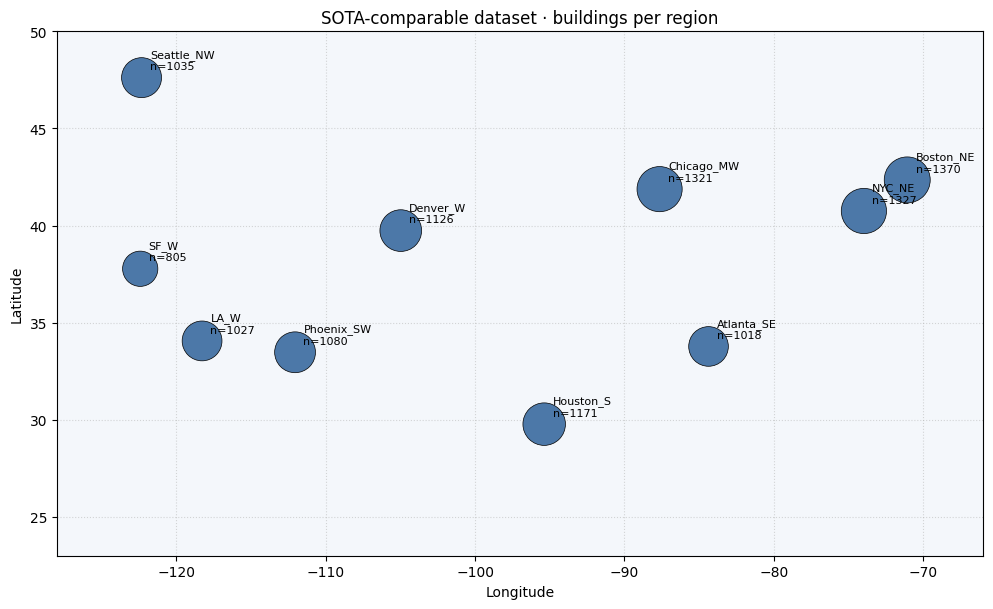

In [6]:
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.set_xlim(-128, -66)
ax.set_ylim(23, 50)
ax.set_aspect(1.3)
ax.set_facecolor("#f4f7fb")
ax.grid(True, linestyle=":", alpha=0.5)
ax.set_title("SOTA-comparable dataset · buildings per region")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

sizes = counts_by_region.reindex(region_meta["region"]).fillna(0)["n"]
ax.scatter(
    region_meta["lon"],
    region_meta["lat"],
    s=sizes.to_numpy() * 0.8,
    c="#4C78A8",
    edgecolors="k",
    linewidths=0.5,
    zorder=3,
)
for _, r in region_meta.iterrows():
    n = int(counts_by_region.loc[r["region"], "n"]) if r["region"] in counts_by_region.index else 0
    ax.annotate(f"{r['region']}\nn={n}", (r["lon"], r["lat"]), textcoords="offset points", xytext=(6, 6), fontsize=8)

fig.tight_layout()
map_path = OUT_DIR / "dataset_coverage_map.png"
fig.savefig(map_path, dpi=150)
print("Saved", map_path)
plt.show()


**Result.** Coverage map of sample counts by metro. Boston/NYC/Chicago are largest; SF is smallest (~805). Good geographic spread for leave-one-region-out tests.

## 2. Extract AlphaEarth embeddings (64-D @ centroid)

Same protocol as notebook 02. Cached under `outputs/sota_building_type/`.


In [7]:
BANDS = [f"A{i:02d}" for i in range(64)]
CACHE_EMB = OUT_DIR / "buildings_with_embeddings.parquet"


def init_ee(project: str) -> None:
    if not project or project == "YOUR_EE_PROJECT_ID":
        raise ValueError("Set EE_PROJECT to your Earth Engine Cloud project id.")
    try:
        ee.Initialize(project=project)
    except Exception:
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=project)
    print("Earth Engine initialized ·", project)


def annual_embedding_image(year: int) -> ee.Image:
    return (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
        .mosaic()
    )


def extract_embeddings(df: pd.DataFrame, year: int = EMBED_YEAR, batch_size: int = EE_BATCH) -> pd.DataFrame:
    init_ee(EE_PROJECT)
    img = annual_embedding_image(year)
    rows: list[dict] = []
    n = len(df)
    for start in range(0, n, batch_size):
        batch = df.iloc[start : start + batch_size]
        feats = [
            ee.Feature(
                ee.Geometry.Point([float(r.lon), float(r.lat)]),
                {"row_id": str(r.id)},
            )
            for r in batch.itertuples()
        ]
        fc = ee.FeatureCollection(feats)
        sampled = img.reduceRegions(
            collection=fc,
            reducer=ee.Reducer.first(),
            scale=10,
            tileScale=4,
        )
        print(f"EE reduceRegions · {start}:{start + len(batch)} / {n}", flush=True)
        info = sampled.getInfo()
        for f in info["features"]:
            props = f["properties"]
            row = {"id": props.get("row_id")}
            for b in BANDS:
                row[b] = props.get(b)
            rows.append(row)
        time.sleep(0.4)
    emb = pd.DataFrame(rows).dropna(subset=BANDS).reset_index(drop=True)
    return emb


if CACHE_EMB.exists():
    dataset = pd.read_parquet(CACHE_EMB)
    print("Loaded", CACHE_EMB, "· n =", len(dataset))
else:
    emb = extract_embeddings(labels)
    dataset = labels.merge(emb, on="id", how="inner")
    dataset.to_parquet(CACHE_EMB, index=False)
    print("Wrote", CACHE_EMB, "· n =", len(dataset))

# sanity: unit-ish norms
X = dataset[BANDS].to_numpy(dtype=float)
norms = np.linalg.norm(X, axis=1)
print(f"Embedding L2 norms · mean={norms.mean():.3f} std={norms.std():.3f}")
print(dataset.groupby("label").size().reindex(LABEL_ORDER).dropna())


Earth Engine initialized · ee-kedarvaidya0504
EE reduceRegions · 0:400 / 11280
EE reduceRegions · 400:800 / 11280
EE reduceRegions · 800:1200 / 11280
EE reduceRegions · 1200:1600 / 11280
EE reduceRegions · 1600:2000 / 11280
EE reduceRegions · 2000:2400 / 11280
EE reduceRegions · 2400:2800 / 11280
EE reduceRegions · 2800:3200 / 11280
EE reduceRegions · 3200:3600 / 11280
EE reduceRegions · 3600:4000 / 11280
EE reduceRegions · 4000:4400 / 11280
EE reduceRegions · 4400:4800 / 11280
EE reduceRegions · 4800:5200 / 11280
EE reduceRegions · 5200:5600 / 11280
EE reduceRegions · 5600:6000 / 11280
EE reduceRegions · 6000:6400 / 11280
EE reduceRegions · 6400:6800 / 11280
EE reduceRegions · 6800:7200 / 11280
EE reduceRegions · 7200:7600 / 11280
EE reduceRegions · 7600:8000 / 11280
EE reduceRegions · 8000:8400 / 11280
EE reduceRegions · 8400:8800 / 11280
EE reduceRegions · 8800:9200 / 11280
EE reduceRegions · 9200:9600 / 11280
EE reduceRegions · 9600:10000 / 11280
EE reduceRegions · 10000:10400 / 11

**Result.** AlphaEarth embeddings pulled for all **11,280** buildings (0 dropped). Vectors are unit-length (L2 ≈ 1.0) as expected. Feature matrix is ready for a simple classifier.

## 3. Multi-modal-ready export + splits

Columns for future modalities (not filled here):

| Future field | Role |
|---|---|
| `wkt` | footprint for VHR / GSV frustum / polygon-mean pooling |
| `lon`,`lat` | GSV lookup / neighbor graph nodes |
| `height`,`num_floors` | weak 3D priors (often sparse) |
| `A00`…`A63` | AlphaEarth (available now) |

SOTA papers typically add street-level crops + satellite VHR patches + street/parcel graphs on top.


In [8]:
# Canonical column order
meta_cols = [
    "id",
    "region",
    "lon",
    "lat",
    "wkt",
    "subtype",
    "class",
    "label",
    "y_res",
    "height",
    "num_floors",
    "area_m2_approx",
    "source_primary",
]
meta_cols = [c for c in meta_cols if c in dataset.columns]
export = dataset[meta_cols + BANDS].copy()

# Region-holdout friendly split tags (analysis notebooks can re-split)
rng = np.random.default_rng(RANDOM_STATE)
export["split_seed"] = rng.integers(0, 10_000, size=len(export))

dataset_path = OUT_DIR / "dataset.parquet"
export.to_parquet(dataset_path, index=False)

# Also write a lightweight CSV without WKT / embeddings for quick browsing
browse = export.drop(columns=["wkt"] + BANDS, errors="ignore")
browse_path = OUT_DIR / "dataset_browse.csv"
browse.to_csv(browse_path, index=False)

manifest = {
    "name": "sota_comparable_building_type_v1",
    "purpose": (
        "Multi-class building-type dataset for comparing AlphaEarth+simple-classifier "
        "against SOTA that uses street-view / VHR / multi-modal graphs (typically 86-96% "
        "on 10-12 classes)."
    ),
    "overture_release": RELEASE,
    "embedding": {
        "collection": "GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL",
        "year": EMBED_YEAR,
        "bands": BANDS,
        "sample": "centroid Reducer.first @ 10m",
    },
    "label_source": "Overture buildings.class (OSM-derived); ambiguous classes excluded",
    "taxonomy": LABEL_ORDER,
    "class_to_label": CLASS_TO_LABEL,
    "n_buildings": int(len(export)),
    "n_regions": int(export["region"].nunique()),
    "regions": sorted(export["region"].unique().tolist()),
    "label_counts": export["label"].value_counts().to_dict(),
    "files": {
        "dataset_parquet": str(dataset_path.relative_to(ROOT)),
        "browse_csv": str(browse_path.relative_to(ROOT)),
        "label_counts": str(counts_path.relative_to(ROOT)),
    },
    "sota_reference_notes": [
        "HeteroGNN + hierarchical urban features + cross-view imagery: ~86-96% acc on 10-12 types",
        "GHS-OBAT: global res/non-res attributes on Overture footprints (different GT/modality)",
        "This dataset provides AlphaEarth-only features now; GSV/VHR/graph columns to be joined later",
    ],
    "ee_project_used": EE_PROJECT,
}
manifest_path = OUT_DIR / "manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))
print("Wrote", dataset_path)
print("Wrote", browse_path)
print("Wrote", manifest_path)
print(json.dumps({k: manifest[k] for k in ["n_buildings", "n_regions", "label_counts"]}, indent=2))


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/dataset.parquet
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/dataset_browse.csv
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/manifest.json
{
  "n_buildings": 11280,
  "n_regions": 10,
  "label_counts": {
    "single_family": 1987,
    "education": 1840,
    "retail": 1616,
    "industrial": 1287,
    "multi_family": 1102,
    "religious": 802,
    "civic": 757,
    "office": 756,
    "medical": 594,
    "hotel": 539
  }
}


**Result.** Exported the final dataset: **11,280** buildings × 10 regions. Biggest classes: single_family (1,987), education (1,840), retail (1,616). Smallest: hotel (539), medical (594). Files ready under `outputs/sota_building_type/`.

## 4. Dataset QA summary

Analysis of AlphaEarth + simple classifier performance will use `dataset.parquet` in a follow-up
notebook / cells. Quick QA below.


In [9]:
qa = pd.DataFrame(
    {
        "n": export.groupby("region").size(),
        "n_labels": export.groupby("region")["label"].nunique(),
        "pct_residential": export.groupby("region")["y_res"].mean() * 100,
        "pct_has_height": export.groupby("region")["height"].apply(lambda s: 100 * s.notna().mean())
        if "height" in export.columns
        else np.nan,
    }
).sort_values("n", ascending=False)

qa_path = OUT_DIR / "qa_by_region.csv"
qa.to_csv(qa_path)
print("Wrote", qa_path)
qa


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/qa_by_region.csv


,n,n_labels,pct_residential,pct_has_height
region,,,,
Boston_NE,1370,10,29.489,96.423
NYC_NE,1327,10,25.396,96.383
Chicago_MW,1321,10,26.419,94.928
Houston_S,1171,10,27.754,92.400
Denver_W,1126,10,28.064,89.076
Phoenix_SW,1080,10,28.519,93.333
Seattle_NW,1035,10,33.237,97.295
LA_W,1027,10,18.014,99.221
Atlanta_SE,1018,10,31.238,88.802


**Result.** All 10 metros have all 10 labels. Sample sizes ~800–1,370 each. Residential share is ~18–33% (by design, not balanced binary). Height is available for ~89–99% of buildings — useful later as a weak extra feature.

## Done

Artifacts in `outputs/sota_building_type/`:

- `dataset.parquet` — full multi-modal-ready table + AlphaEarth bands
- `dataset_browse.csv` — labels/coords only
- `manifest.json` — taxonomy, SOTA comparison notes, file index
- `label_counts_by_region.csv`, `qa_by_region.csv`, `dataset_coverage_map.png`

**Next:** run a simple classifier (LR / HGB) on `A00…A63` → `label`, report accuracy / macro-F1
vs the SOTA 86–96% ballpark, with leave-one-region-out transfer.
